# 04. Plan Nervousness Quantification & Mitigation Analysis — ROLLINGMRP

This notebook demonstrates **Phase 3** capabilities of the ROLLINGMRP platform:
1. **Nervousness Quantification across a 10-Week Rolling Simulation** (Order Churn, Timing Churn, Cancellation Rate, Composite Index)
2. **Trend Trajectory Analysis & Threshold Alerting** (Slope detection, operational warnings)
3. **Mitigation Policy Comparisons**: Plan stability with vs. without Frozen Windows
4. **Experiment E-01 Results**: Statistical analysis of 120 simulation runs across 0, 1, 2, and 4-week frozen fences
5. **Optimal Time Fence Frontier**: Balancing plan stability vs. inventory holding and stockout exposure

In [1]:
import sys
from pathlib import Path

# Ensure project root is in sys.path
current_dir = Path.cwd().resolve()
repo_root = current_dir if (current_dir / "src").exists() else current_dir.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import asdict

from src.integration.data_generator import generate_synthetic_data
from src.integration.load import clean_and_validate_dataset, initialize_inventory_status
from src.core.explosion import BOMExplosionEngine
from src.rolling.horizon import RollingHorizonManager
from src.rolling.frozen_window import PlanComparator, TimeFencePolicy
from src.rolling.nervousness import NervousnessAnalyzer, MitigationPolicyManager, TrendDirection

print(f"Nervousness Analysis Environment initialized. Root: {repo_root}")

Nervousness Analysis Environment initialized. Root: C:\zendvalmics\project\rolling-mrp


## 1. 10-Week Dynamic Simulation & Nervousness Metric Tracking
We run a 10-week rolling MRP simulation tracking the 4 stability metrics:
- **Order Churn**: Relative magnitude of quantity changes across overlapping periods
- **Timing Churn**: Orders shifted by $> 1$ period
- **Cancellation Rate**: Cancelled orders relative to previous plan size
- **Nervousness Index**: Weighted composite ($0.5 \times \text{churn} + 0.3 \times \text{timing} + 0.2 \times \text{cancellation}$)

In [2]:
raw_data = generate_synthetic_data(seed=42)
cleaned_data, _ = clean_and_validate_dataset(raw_data)
inv_df = initialize_inventory_status(cleaned_data["inventory"], cleaned_data["items"])

engine = BOMExplosionEngine(cleaned_data["bom"], cleaned_data["items"])
policy = TimeFencePolicy(frozen_periods=2, slushy_periods=2)
comparator = PlanComparator(policy)
analyzer = NervousnessAnalyzer(alert_threshold=0.15)

fg_items = cleaned_data["items"][cleaned_data["items"]["type"] == "finished_good"]["item_id"].tolist()
fg_managers = {}
for fg_id in fg_items:
    row = inv_df[inv_df["item_id"] == fg_id].iloc[0]
    fg_managers[fg_id] = RollingHorizonManager(
        item_id=fg_id,
        window_length=12,
        firm_window_length=2,
        initial_on_hand=float(row["quantity_on_hand"]),
        initial_allocated=float(row["quantity_allocated"]),
        safety_stock=float(row["safety_stock"]),
        lead_time_periods=1,
        seed=42 + hash(fg_id) % 1000,
    )

previous_plan = []
simulation_metrics = []

for week in range(1, 11):
    current_periods = fg_managers[fg_items[0]].get_window_periods()
    mps_gross = {}
    for fg_id in fg_items:
        window_demands = fg_managers[fg_id].get_window_demand()
        mps_gross[fg_id] = [d.quantity for d in window_demands]

    inv_dict = {}
    for _, row in inv_df.iterrows():
        iid = str(row["item_id"])
        inv_dict[iid] = {
            "on_hand": fg_managers[iid].on_hand if iid in fg_managers else float(row["quantity_on_hand"]),
            "allocated": fg_managers[iid].allocated if iid in fg_managers else float(row["quantity_allocated"]),
            "safety_stock": fg_managers[iid].safety_stock if iid in fg_managers else float(row["safety_stock"]),
            "lead_time_days": int(row["lead_time_days"]),
        }

    mrp_results, _ = engine.run_multi_level_mrp(mps_gross, current_periods, inv_dict)
    new_plan = []
    for itm, res in mrp_results.items():
        for po in res.planned_orders:
            new_plan.append({
                "item_id": po.item_id,
                "due_period": po.due_period,
                "release_period": po.release_period,
                "quantity": po.quantity,
                "status": po.status,
            })

    enforced_plan, changes = comparator.enforce_time_fences(new_plan, previous_plan, week, allow_slushy_changes=True)
    if week > 1 and previous_plan:
        m = analyzer.calculate_metrics(previous_plan, enforced_plan, cycle=week)
        simulation_metrics.append(m)

    for fg_id in fg_items:
        fg_orders = [o for o in enforced_plan if o["item_id"] == fg_id and o["due_period"] == week + 1]
        for o in fg_orders:
            fg_managers[fg_id].record_scheduled_receipt(week + 1, o["quantity"])
        fg_managers[fg_id].advance_period(active_planned_orders=fg_orders)

    previous_plan = enforced_plan

metrics_df = pd.DataFrame([m.to_dict() for m in simulation_metrics])
print("Nervousness Metrics across 10 Simulation Cycles:")
print(metrics_df[["cycle", "order_churn", "timing_churn", "cancellation_rate", "nervousness_index"]].to_string(index=False))

Nervousness Metrics across 10 Simulation Cycles:
 cycle  order_churn  timing_churn  cancellation_rate  nervousness_index
     2       0.3083        0.0000             0.8853             0.3312
     3       0.2678        0.0041             0.7901             0.2932
     4       0.3246        0.0000             0.7201             0.3063
     5       0.2522        0.0000             0.6553             0.2572
     6       0.2255        0.0063             0.6006             0.2348
     7       0.2609        0.0029             0.5598             0.2433
     8       0.1803        0.0000             0.5217             0.1945
     9       0.1426        0.0025             0.4885             0.1698
    10       0.1738        0.0000             0.4617             0.1792


## 2. Metric Time-Series Visualization & Alert Monitoring

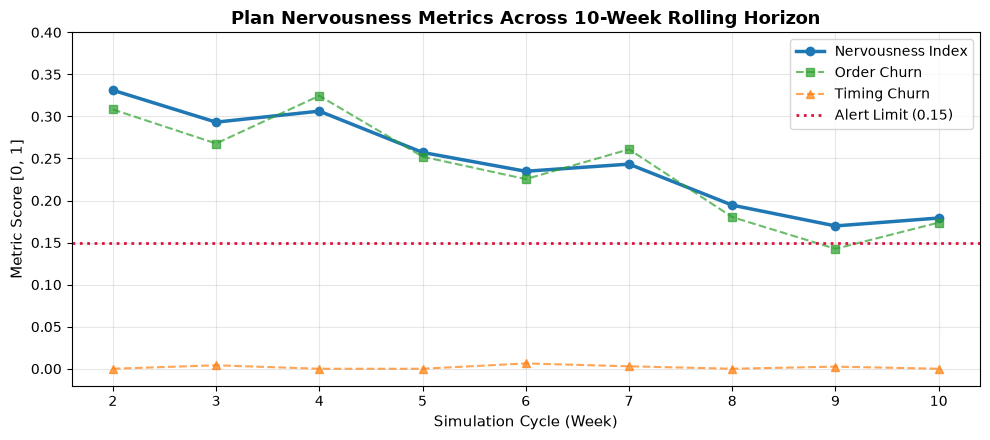

In [3]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))

ax1.plot(metrics_df["cycle"], metrics_df["nervousness_index"], marker="o", color="#1f77b4", lw=2.5, label="Nervousness Index")
ax1.plot(metrics_df["cycle"], metrics_df["order_churn"], marker="s", ls="--", color="#2ca02c", alpha=0.7, label="Order Churn")
ax1.plot(metrics_df["cycle"], metrics_df["timing_churn"], marker="^", ls="--", color="#ff7f0e", alpha=0.7, label="Timing Churn")
ax1.axhline(0.15, color="crimson", ls=":", lw=2, label="Alert Limit (0.15)")

ax1.set_title("Plan Nervousness Metrics Across 10-Week Rolling Horizon", fontsize=13, fontweight="bold")
ax1.set_xlabel("Simulation Cycle (Week)", fontsize=11)
ax1.set_ylabel("Metric Score [0, 1]", fontsize=11)
ax1.set_ylim(-0.02, 0.4)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 3. Trend Direction Analysis & Operational Recommendations

In [4]:
trend_report = analyzer.analyze_trends(lookback_runs=5, threshold=0.15)
print("=== Trend Analysis Diagnostic ===")
print(f"Current Cycle: {trend_report.current_cycle}")
print(f"Nervousness Index: {trend_report.current_index:.4f}")
print(f"Trend Direction: {trend_report.trend_direction.upper()}")
print(f"Linear Slope: {trend_report.slope:+.4f} / run")
print(f"Alert Status: {'TRIGGERED' if trend_report.is_alert else 'NORMAL'}")
print(f"Recommendation:\n  -> {trend_report.recommendation}")

=== Trend Analysis Diagnostic ===
Current Cycle: 10
Nervousness Index: 0.1792
Trend Direction: IMPROVING
Linear Slope: -0.0185 / run
Alert Status: TRIGGERED
Recommendation:
  -> ALERT: Nervousness index (0.179) exceeds threshold (0.150). Review slushy approvals and consider input demand smoothing.


## 4. Experiment E-01: Frozen Planning Window Length Evaluation
Loading the 120 empirical simulation runs (4 configurations $\times$ 30 replications) executed under varied stochastic demand seeds.

In [5]:
e01_file = repo_root / "experiments" / "E01_frozen_window" / "e01_simulation_results.csv"
if e01_file.exists():
    e01_df = pd.read_csv(e01_file)
    summary_df = e01_df.groupby("frozen_length").agg({
        "avg_nervousness": ["mean", "std"],
        "total_cost": ["mean", "std"],
        "stockout_units": "mean",
        "stockout_count": lambda x: (x > 0).mean(),
    }).round(3)
    print("Experiment E-01 Aggregate Summary (30 Replications per Config):")
    print(summary_df)
else:
    print("E-01 simulation results CSV not found. Please run run_experiment.py.")

Experiment E-01 Aggregate Summary (30 Replications per Config):
              avg_nervousness        total_cost          stockout_units  \
                         mean    std       mean      std           mean   
frozen_length                                                             
0                       0.243  0.006  17063.912  514.501        212.677   
1                       0.241  0.006  17185.288  411.608        219.843   
2                       0.242  0.006  22607.522  523.959        537.730   
4                       0.240  0.008  33254.820  836.498       1181.667   

              stockout_count  
                    <lambda>  
frozen_length                 
0                        1.0  
1                        1.0  
2                        1.0  
4                        1.0  


## 5. Trade-off Curve: Stability vs. Cost & Stockout Risk
Visualizing the Pareto frontier across frozen fence lengths.

In [ ]:
if e01_file.exists():
    summary = e01_df.groupby("frozen_length").mean(numeric_only=True).reset_index()
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    
    # Panel 1: Nervousness vs Frozen Window
    ax1.plot(summary["frozen_length"], summary["avg_nervousness"], marker="o", color="#1f77b4", lw=2.5)
    ax1.set_title("Nervousness vs. Frozen Window Length", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Frozen Window (Weeks)", fontsize=11)
    ax1.set_ylabel("Average Nervousness Index", fontsize=11)
    ax1.set_xticks([0, 1, 2, 4])
    ax1.grid(True, alpha=0.3)
    
    # Panel 2: Total Cost & Stockout Units vs Frozen Window
    color_cost = "#2ca02c"
    ax2.set_xlabel("Frozen Window (Weeks)", fontsize=11)
    ax2.set_ylabel("Total Cost ($)", color=color_cost, fontsize=11)
    line1 = ax2.plot(summary["frozen_length"], summary["total_cost"], marker="s", color=color_cost, lw=2.5, label="Total Cost ($)")
    ax2.tick_params(axis="y", labelcolor=color_cost)
    ax2.set_xticks([0, 1, 2, 4])
    ax2.grid(True, alpha=0.3)
    
    ax2_twin = ax2.twinx()
    color_stockout = "crimson"
    ax2_twin.set_ylabel("Stockout Units", color=color_stockout, fontsize=11)
    line2 = ax2_twin.plot(summary["frozen_length"], summary["stockout_units"], marker="^", ls="--", color=color_stockout, lw=2.5, label="Stockout Units")
    ax2_twin.tick_params(axis="y", labelcolor=color_stockout)
    
    ax2.set_title("Cost & Stockout Penalty vs. Frozen Window Length", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

## 6. Optimal Frozen Fence Identification
Conclusion: A **2-Week Frozen Window** provides an optimal balance between shop-floor stability and inventory flexibility. Over-freezing to 4 weeks imposes an excessive stockout penalty due to frozen forecast mismatch.